# ДЗ: анализ TCR-репертуаров (nCD4 и nCD8)

Повторяем пайплайн с семинара (где разбирали `nTreg`) для наивных `nCD4` и `nCD8` Т-клеток (цепь TRB). Подбираем нормальные пороги даунсэмплирования под эти выборки, считаем основные метрики, проверяем, как на них влияет глубина, и смотрим, что меняется с возрастом.

In [1]:
import os
from pathlib import Path
import pandas as pd
from pandas.api.types import CategoricalDtype
import matplotlib.pyplot as plt
import seaborn as sns

from repseq import clonosets as cl
from repseq import clone_filter as clf
import repseq
from repseq import stats
stats.AA_PROPS_PATH = os.path.join(os.path.dirname(repseq.__file__), "resourses", "aa_property_table.txt")
from repseq import plot as rsplot
from repseq import beta

PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "environment.yml").is_file() and (p / "notebooks").is_dir()
)
WORKING_DIR = str(PROJECT_ROOT / "outputs" / "repseq_hw")
os.makedirs(WORKING_DIR, exist_ok=True)

clonosets_ucb_dir = str(PROJECT_ROOT / "data" / "ucb_figshare")
clonosets = cl.find_all_mixcr_clonosets(clonosets_ucb_dir, show_offtarget=False, offtarget_threshold=0.01)

exp_group_order = CategoricalDtype(
    categories=['preterm', 'term', 'late', 'children', 'adults', 'older_adults'],
    ordered=True
)
subset_order = CategoricalDtype(categories=["nCD4", "nTreg", "nCD8"], ordered=True)

metadata = pd.read_csv(os.path.join(clonosets_ucb_dir, "ucb_figshare_TRB_metadata.csv"))[
    ["sample_id", "experimental_group", "donor_id", "subset"]
]
metadata["experimental_group"] = metadata["experimental_group"].astype(exp_group_order)
metadata["subset"] = metadata["subset"].astype(subset_order)
metadata["source"] = metadata["experimental_group"].apply(
    lambda x: "UCB" if x in ['preterm', 'term', 'late'] else "PB"
)

func_filter = clf.Filter(functionality="f", by_umi=True)
print("Всего файлов в папке:", len(clonosets))

Всего файлов в папке: 87


## nCD4

Сначала смотрим, сколько образцов в каждой группе и какой у них размер. В `nCD4` всего 30 образцов. Самый маленький — `c2_mnCD4_TRB_1` из группы `children`, у него 5912 функциональных наблюдений (`reads_func`). В группе `children` всего 4 образца, выкидывать её не хочется, поэтому беру `downsample=5500` (с `seed=100`). Потом для проверки устойчивости пересчитаю альфа-разнообразие на `2500`.

experimental_group
preterm         3
term            6
late            4
children        4
adults          9
older_adults    4
Name: count, dtype: int64

Using 4 cores


CalcClonosetStats |##################################################| 30/30 calcultaion(s) processed


,sample_id,clones_func,reads_func,clones_nonfunc_freq
8,c2_mnCD4_TRB_1,4508,5912,0.034069
20,c4_mnCD4_TRB_1,9515,13695,0.040052
2,a7_mnCD4_TRB_1,14760,22220,0.041247
25,UCB4_nCD4_TRB_1,14235,23395,0.051253
16,c5_mnCD4_TRB_1,25952,32077,0.027031
24,UCB6_nCD4_TRB_1,22069,33053,0.042809
11,UCB12_mnCD4_TRB_1,27005,33459,0.040675
19,a9_mnCD4_TRB_1,23743,35572,0.032320
10,o5_mnCD4_TRB_1,17835,35797,0.065105
14,a1_mnCD4_TRB_1,25444,38486,0.040573


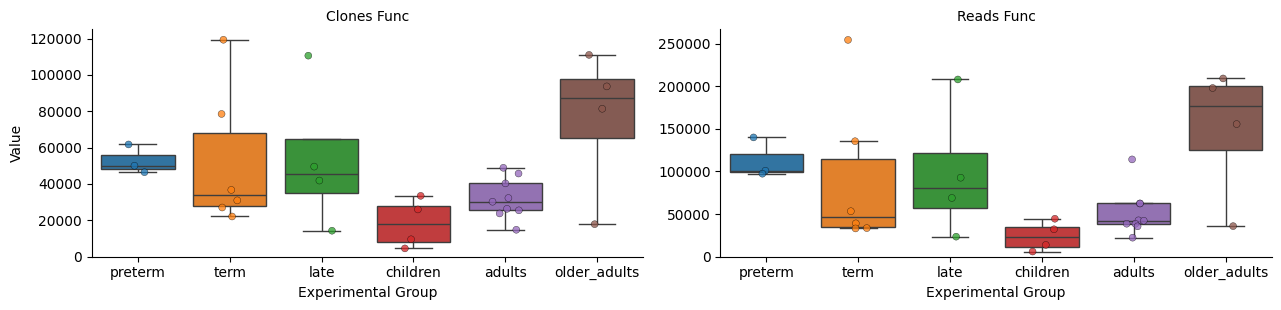

In [2]:
clonosets_cd4 = clonosets.merge(metadata).query("subset == 'nCD4'").reset_index(drop=True)
display(clonosets_cd4["experimental_group"].value_counts().sort_index())

stats_cd4 = stats.calc_clonoset_stats(clonosets_cd4, cpu=4)
display(stats_cd4.sort_values("reads_func").head(10)[["sample_id", "clones_func", "reads_func", "clones_nonfunc_freq"]])

rsplot.clonoset_stats(stats_cd4, metadata=metadata, group="experimental_group", properties=["clones_func", "reads_func"], aspect=2)
plt.show()

ds_cd4_main = clf.Filter(functionality="f", downsample=5500, by_umi=True, seed=100)
ds_cd4_alt  = clf.Filter(functionality="f", downsample=2500, by_umi=True, seed=100)

### Свойства и длины CDR3 (nCD4)

Using 4 cores


CalcCDR3aaProperties |##################################################| 30/30 calcultaion(s) processed


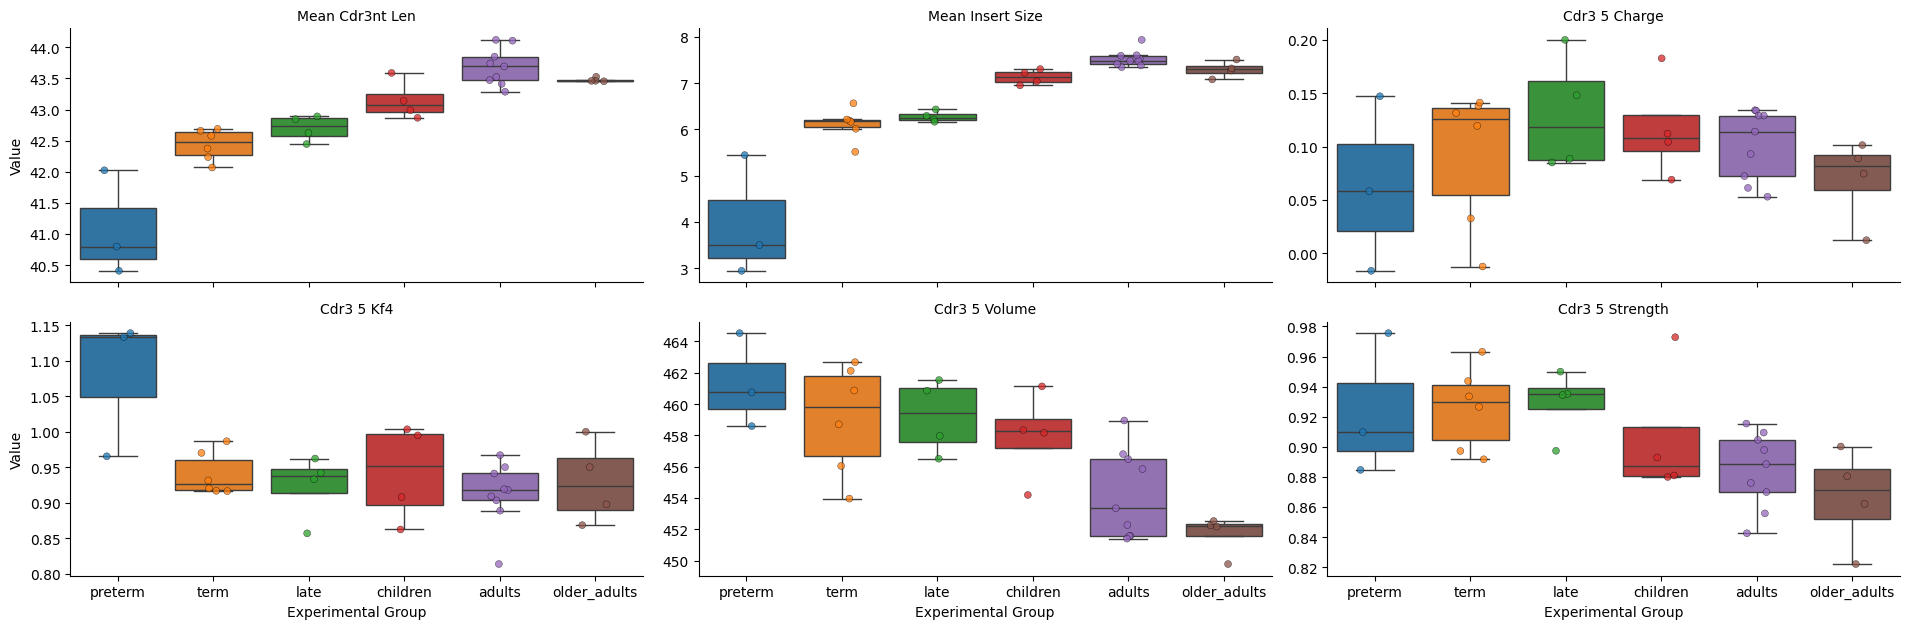

In [3]:
cdr3_props_cd4 = stats.calc_cdr3_properties(clonosets_cd4, cl_filter=func_filter, cpu=4)
cdr3_props_cd4.to_csv(os.path.join(WORKING_DIR, "cdr3_properties_nCD4.csv"), index=False)
rsplot.cdr3aa_stats(cdr3_props_cd4, metadata=metadata, group="experimental_group", height=3.2, aspect=2)
plt.show()

preterm_late_cd4 = clonosets_cd4.query("experimental_group in ['preterm', 'late']")
cdr3_len_cd4 = stats.cdr3_length_distributions(
    preterm_late_cd4, cl_filter=func_filter, cpu=4,
    count_by_freq=True, seq_type="aa", table="long", zero_fill=True, verbose=False
)
rsplot.cdr3_length_distributions(cdr3_len_cd4, metadata=metadata, group="experimental_group")
plt.show()

### V-сегменты и конвергенция (nCD4)

Using 4 cores


CalcSegmentUsage |##################################################| 30/30 calcultaion(s) processed


CalcConvergence settings: seed=None, downsample=5500, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 4 cores


CalcClonosetStats |##################################################| 30/30 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): UCB5_nCD4_TRB_2, UCB2_nCD4_TRB_1, a7_mnCD4_TRB_1, UCB3_nCD4_TRB_1, UCB9_nCD4_TRB_2, a11_mnCD4_TRB_1, a15_mnCD4_TRB_1, c1_mnCD4_TRB_1, c2_mnCD4_TRB_1, UCB7_nCD4_TRB_1, o5_mnCD4_TRB_1, UCB12_mnCD4_TRB_1, o3_mnCD4_TRB_2, a10_mnCD4_TRB_1, a1_mnCD4_TRB_1, UCB8_nCD4_TRB_1, c5_mnCD4_TRB_1, a5_mnCD4_TRB_1, a3_mnCD4_TRB_1, a9_mnCD4_TRB_1, c4_mnCD4_TRB_1, UCB13_mnCD4_TRB_1, UCB10_nCD4_TRB_1, a13_mnCD4_TRB_1, UCB6_nCD4_TRB_1, UCB4_nCD4_TRB_1, UCB11_nCD4_TRB_1, o1_mnCD4_TRB_1, o6_mnCD4_TRB_2, UCB1_nCD4_TRB_2
These samples will be counted by reads instead
WARNING! Random filter is applied, but random seed is not set. This may lead to non-reproducible results.
You may set the seed (of any hashable type) by specifying 'seed='
Using 4 cores


CalcConvergence |##################################################| 30/30 calcultaion(s) processed


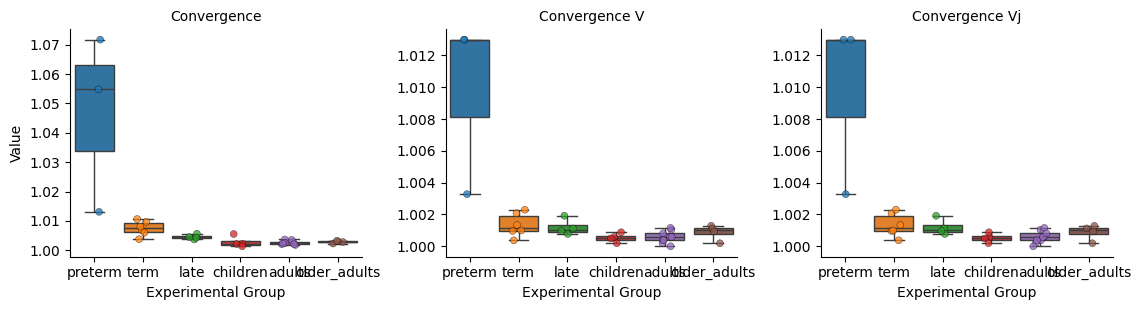

In [4]:
v_usage_cd4 = stats.calc_segment_usage(clonosets_cd4, cl_filter=func_filter, segment="V", cpu=4)
rsplot.segment_usage(v_usage_cd4, metadata=metadata, group="experimental_group")
plt.show()

conv_cd4 = stats.calc_convergence(clonosets_cd4, cl_filter=ds_cd4_main, cpu=4)
rsplot.convergence(conv_cd4, metadata=metadata, group="experimental_group")
plt.show()

### Альфа-разнообразие, rarefaction и проверка глубины даунсэмпла (nCD4)

CalcDiversityStats settings: seed=None, downsample=5500, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 4 cores


CalcClonosetStats |##################################################| 30/30 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): UCB5_nCD4_TRB_2, UCB2_nCD4_TRB_1, a7_mnCD4_TRB_1, UCB3_nCD4_TRB_1, UCB9_nCD4_TRB_2, a11_mnCD4_TRB_1, a15_mnCD4_TRB_1, c1_mnCD4_TRB_1, c2_mnCD4_TRB_1, UCB7_nCD4_TRB_1, o5_mnCD4_TRB_1, UCB12_mnCD4_TRB_1, o3_mnCD4_TRB_2, a10_mnCD4_TRB_1, a1_mnCD4_TRB_1, UCB8_nCD4_TRB_1, c5_mnCD4_TRB_1, a5_mnCD4_TRB_1, a3_mnCD4_TRB_1, a9_mnCD4_TRB_1, c4_mnCD4_TRB_1, UCB13_mnCD4_TRB_1, UCB10_nCD4_TRB_1, a13_mnCD4_TRB_1, UCB6_nCD4_TRB_1, UCB4_nCD4_TRB_1, UCB11_nCD4_TRB_1, o1_mnCD4_TRB_1, o6_mnCD4_TRB_2, UCB1_nCD4_TRB_2
These samples will be counted by reads instead
WARNING! Random filter is applied, but random seed is not set. This may lead to non-reproducible results.
You may set the seed (of any hashable type) by specifying 'seed='
Using 4 cores


CalcDiversityStats |##################################################| 30/30 calcultaion(s) processed


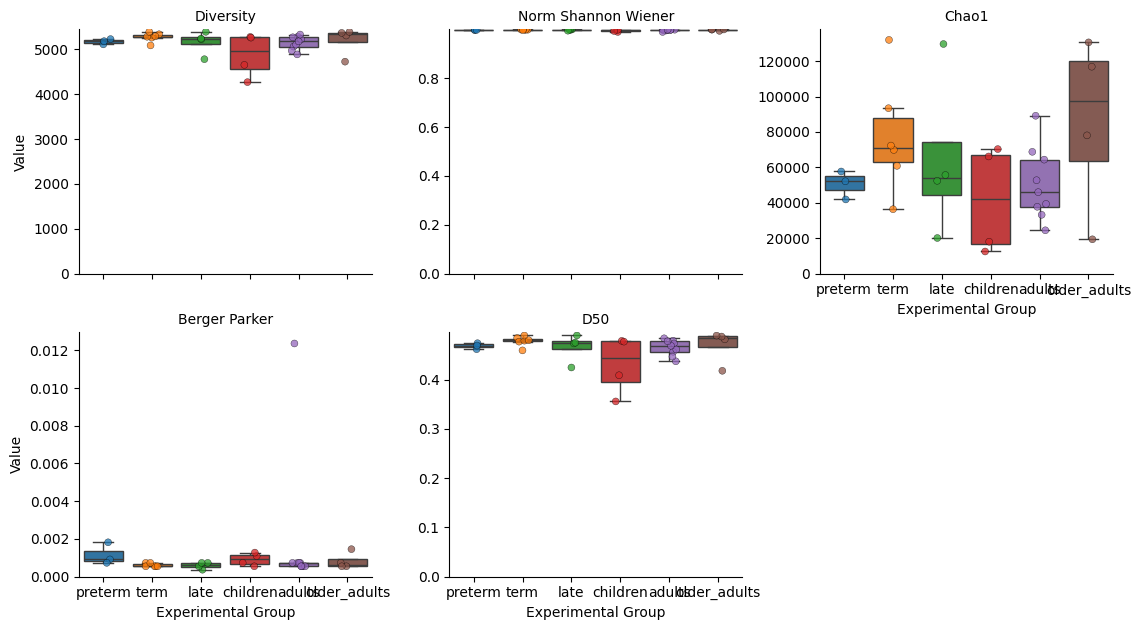

Using 4 cores


CalcRarefactionPoints |##################################################| 30/30 calcultaion(s) processed


CalcDiversityStats settings: seed=None, downsample=2500, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 4 cores


CalcClonosetStats |##################################################| 30/30 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): UCB5_nCD4_TRB_2, UCB2_nCD4_TRB_1, a7_mnCD4_TRB_1, UCB3_nCD4_TRB_1, UCB9_nCD4_TRB_2, a11_mnCD4_TRB_1, a15_mnCD4_TRB_1, c1_mnCD4_TRB_1, c2_mnCD4_TRB_1, UCB7_nCD4_TRB_1, o5_mnCD4_TRB_1, UCB12_mnCD4_TRB_1, o3_mnCD4_TRB_2, a10_mnCD4_TRB_1, a1_mnCD4_TRB_1, UCB8_nCD4_TRB_1, c5_mnCD4_TRB_1, a5_mnCD4_TRB_1, a3_mnCD4_TRB_1, a9_mnCD4_TRB_1, c4_mnCD4_TRB_1, UCB13_mnCD4_TRB_1, UCB10_nCD4_TRB_1, a13_mnCD4_TRB_1, UCB6_nCD4_TRB_1, UCB4_nCD4_TRB_1, UCB11_nCD4_TRB_1, o1_mnCD4_TRB_1, o6_mnCD4_TRB_2, UCB1_nCD4_TRB_2
These samples will be counted by reads instead
WARNING! Random filter is applied, but random seed is not set. This may lead to non-reproducible results.
You may set the seed (of any hashable type) by specifying 'seed='
Using 4 cores


CalcDiversityStats |##################################################| 30/30 calcultaion(s) processed


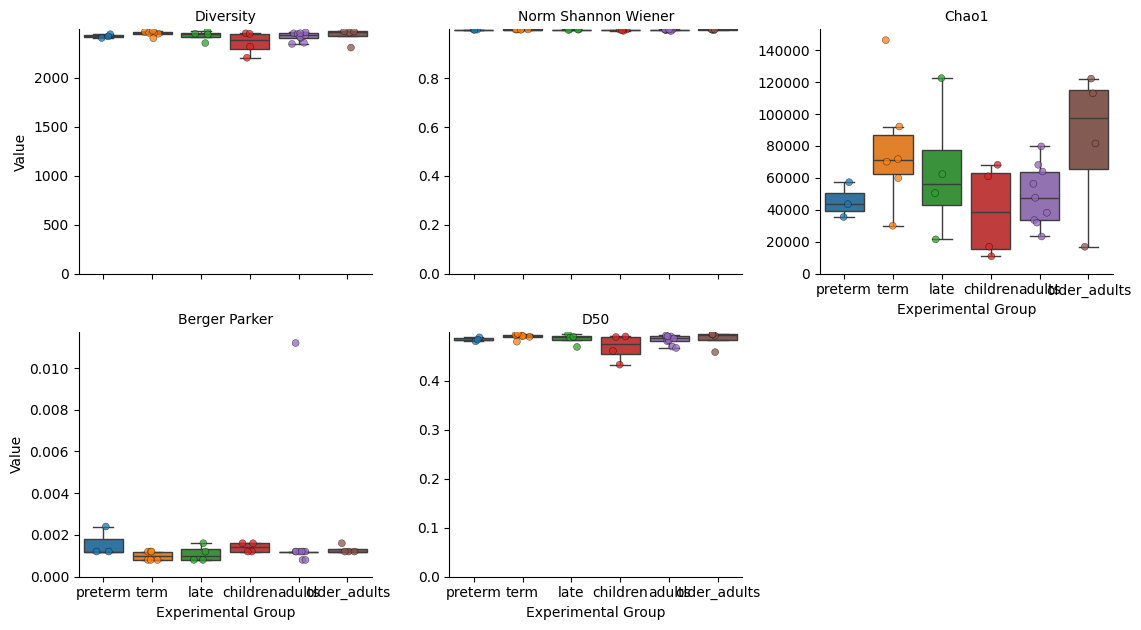

In [5]:
div_cd4_main = stats.calc_diversity_stats(clonosets_cd4, cl_filter=ds_cd4_main, cpu=4)
rsplot.diversity_stats(div_cd4_main, metadata=metadata, group="experimental_group")
plt.show()

rare_cd4 = stats.calc_rarefaction_curve(clonosets_cd4, cl_filter=func_filter, cpu=4)
rsplot.rarefaction_curve(rare_cd4)
plt.show()

# смотрим, что будет при downsample=2500
div_cd4_alt = stats.calc_diversity_stats(clonosets_cd4, cl_filter=ds_cd4_alt, cpu=4)
rsplot.diversity_stats(div_cd4_alt, metadata=metadata, group="experimental_group")
plt.show()

### Бета-разнообразие (F2) и MDS (nCD4)

In [6]:
beta_cd4 = beta.metrics(clonosets_cd4, cl_filter=ds_cd4_main, cpu=4)
rsplot.beta_table(beta_cd4)
plt.show()

mds_cd4 = beta.mds(beta_cd4, metric="f2")
rsplot.beta_mds(mds_cd4, metadata=metadata, group="experimental_group")
plt.show()

Intersecting clones in clonosets
--------------------------------------------------
Overlap type: aaV


Reading clonosets |##################################################| 30/30 sample(s) processed
Using 4 cores


Intersecting clonosets |##################################################| 435/435 pairs processed


## nCD8

Теперь то же самое для `nCD8`. Тут 27 образцов, самые маленькие попали в `older_adults`, минимум у `o7_nCD8_TRB_1` — 6368 `reads_func`. Чтобы не терять образцы из пожилой группы, ставим `downsample=6000` (`seed=100`), а для проверки чувствительности сравним с `3000`.

experimental_group
preterm         3
term            6
late            4
children        4
adults          4
older_adults    6
Name: count, dtype: int64

Using 4 cores


CalcClonosetStats |##################################################| 27/27 calcultaion(s) processed


,sample_id,clones_func,reads_func,clones_nonfunc_freq
11,o7_nCD8_TRB_1,5823,6368,0.024950
20,o2_nCD8_TRB_1,6818,8056,0.036597
14,o3_nCD8_TRB_1,5332,8941,0.053771
24,o4_nCD8_TRB_1,4931,12500,0.064859
26,a5_nCD8_TRB_1,14377,16091,0.048574
12,UCB7_nCD8_TRB_1,15764,19100,0.041119
9,a6_nCD8_TRB_1,19070,20571,0.032569
15,a12_nCD8_TRB_1,20166,21375,0.028238
4,UCB12_nCD8_TRB_1,19465,23304,0.044334
6,UCB4_nCD8_TRB_1,15199,27005,0.046786


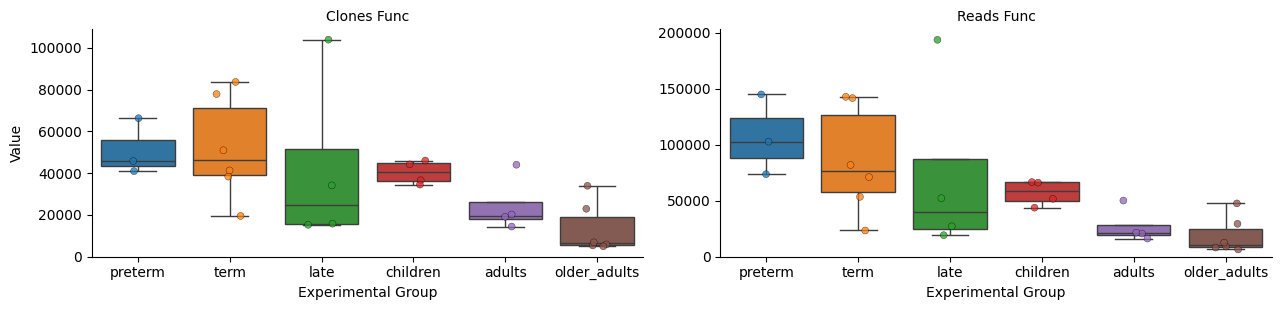

In [7]:
clonosets_cd8 = clonosets.merge(metadata).query("subset == 'nCD8'").reset_index(drop=True)
display(clonosets_cd8["experimental_group"].value_counts().sort_index())

stats_cd8 = stats.calc_clonoset_stats(clonosets_cd8, cpu=4)
display(stats_cd8.sort_values("reads_func").head(10)[["sample_id", "clones_func", "reads_func", "clones_nonfunc_freq"]])

rsplot.clonoset_stats(stats_cd8, metadata=metadata, group="experimental_group", properties=["clones_func", "reads_func"], aspect=2)
plt.show()

ds_cd8_main = clf.Filter(functionality="f", downsample=6000, by_umi=True, seed=100)
ds_cd8_alt  = clf.Filter(functionality="f", downsample=3000, by_umi=True, seed=100)

### Свойства и длины CDR3 (nCD8)

Using 4 cores


CalcCDR3aaProperties |##################################################| 27/27 calcultaion(s) processed


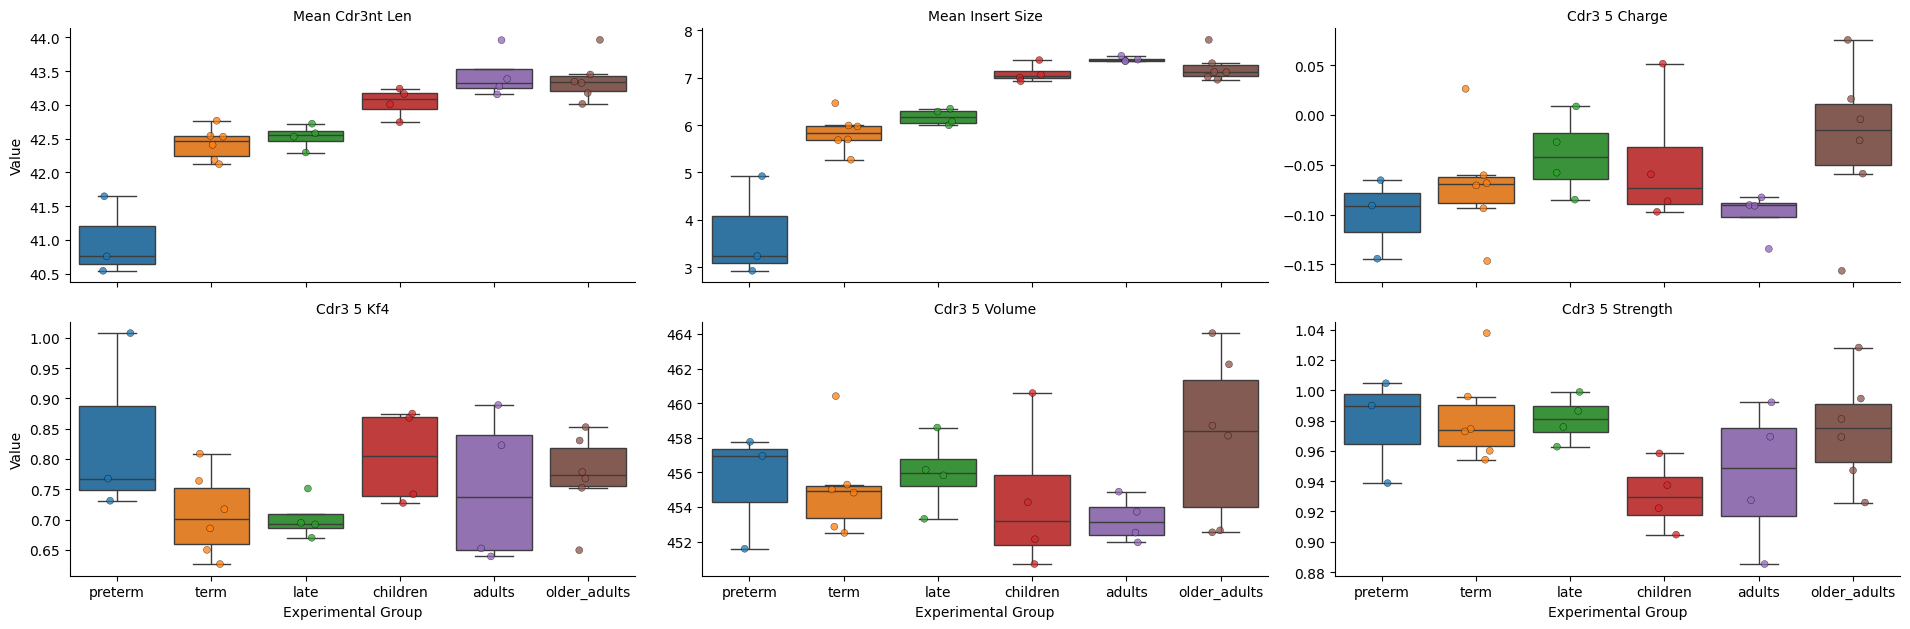

In [8]:
cdr3_props_cd8 = stats.calc_cdr3_properties(clonosets_cd8, cl_filter=func_filter, cpu=4)
cdr3_props_cd8.to_csv(os.path.join(WORKING_DIR, "cdr3_properties_nCD8.csv"), index=False)
rsplot.cdr3aa_stats(cdr3_props_cd8, metadata=metadata, group="experimental_group", height=3.2, aspect=2)
plt.show()

preterm_late_cd8 = clonosets_cd8.query("experimental_group in ['preterm', 'late']")
cdr3_len_cd8 = stats.cdr3_length_distributions(
    preterm_late_cd8, cl_filter=func_filter, cpu=4,
    count_by_freq=True, seq_type="aa", table="long", zero_fill=True, verbose=False
)
rsplot.cdr3_length_distributions(cdr3_len_cd8, metadata=metadata, group="experimental_group")
plt.show()

### V-сегменты и конвергенция (nCD8)

Using 4 cores


CalcSegmentUsage |##################################################| 27/27 calcultaion(s) processed


CalcConvergence settings: seed=None, downsample=6000, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 4 cores


CalcClonosetStats |##################################################| 27/27 calcultaion(s) processed


WARNING! Following samples have NaN downsample counts ('umi_func'): UCB3_nCD8_TRB_1, UCB11_nCD8_TRB_1, c4_nCD8_TRB_1, UCB13_nCD8_TRB_1, UCB12_nCD8_TRB_1, o1_nCD8_TRB_1, UCB4_nCD8_TRB_1, UCB10_nCD8_TRB_1, c1_nCD8_TRB_1, a6_nCD8_TRB_1, UCB2_nCD8_TRB_1, o7_nCD8_TRB_1, UCB7_nCD8_TRB_1, UCB9_nCD8_TRB_1, o3_nCD8_TRB_1, a12_nCD8_TRB_1, UCB6_nCD8_TRB_1, o6_nCD8_TRB_1, UCB8_nCD8_TRB_1, a4_nCD8_TRB_1, o2_nCD8_TRB_1, UCB1_nCD8_TRB_2, c2_nCD8_TRB_1, c5_nCD8_TRB_1, o4_nCD8_TRB_1, UCB5_nCD8_TRB_1, a5_nCD8_TRB_1
These samples will be counted by reads instead
WARNING! Random filter is applied, but random seed is not set. This may lead to non-reproducible results.
You may set the seed (of any hashable type) by specifying 'seed='
Using 4 cores


CalcConvergence |##################################################| 27/27 calcultaion(s) processed


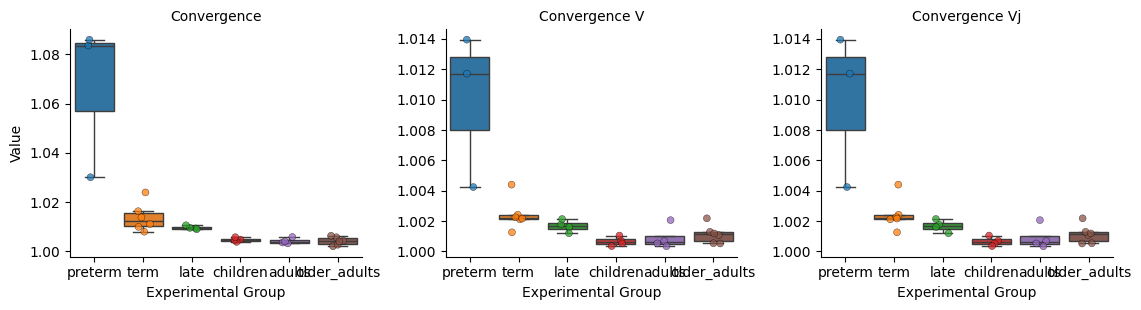

In [9]:
v_usage_cd8 = stats.calc_segment_usage(clonosets_cd8, cl_filter=func_filter, segment="V", cpu=4)
rsplot.segment_usage(v_usage_cd8, metadata=metadata, group="experimental_group")
plt.show()

conv_cd8 = stats.calc_convergence(clonosets_cd8, cl_filter=ds_cd8_main, cpu=4)
rsplot.convergence(conv_cd8, metadata=metadata, group="experimental_group")
plt.show()

### Альфа-разнообразие, rarefaction и проверка глубины даунсэмпла (nCD8)

CalcDiversityStats settings: seed=None, downsample=6000, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 4 cores


CalcClonosetStats |##################################################| 27/27 calcultaion(s) processed
WARNING! Following samples have NaN downsample counts ('umi_func'): UCB3_nCD8_TRB_1, UCB11_nCD8_TRB_1, c4_nCD8_TRB_1, UCB13_nCD8_TRB_1, UCB12_nCD8_TRB_1, o1_nCD8_TRB_1, UCB4_nCD8_TRB_1, UCB10_nCD8_TRB_1, c1_nCD8_TRB_1, a6_nCD8_TRB_1, UCB2_nCD8_TRB_1, o7_nCD8_TRB_1, UCB7_nCD8_TRB_1, UCB9_nCD8_TRB_1, o3_nCD8_TRB_1, a12_nCD8_TRB_1, UCB6_nCD8_TRB_1, o6_nCD8_TRB_1, UCB8_nCD8_TRB_1, a4_nCD8_TRB_1, o2_nCD8_TRB_1, UCB1_nCD8_TRB_2, c2_nCD8_TRB_1, c5_nCD8_TRB_1, o4_nCD8_TRB_1, UCB5_nCD8_TRB_1, a5_nCD8_TRB_1
These samples will be counted by reads instead
WARNING! Random filter is applied, but random seed is not set. This may lead to non-reproducible results.
You may set the seed (of any hashable type) by specifying 'seed='
Using 4 cores


CalcDiversityStats |##################################################| 27/27 calcultaion(s) processed


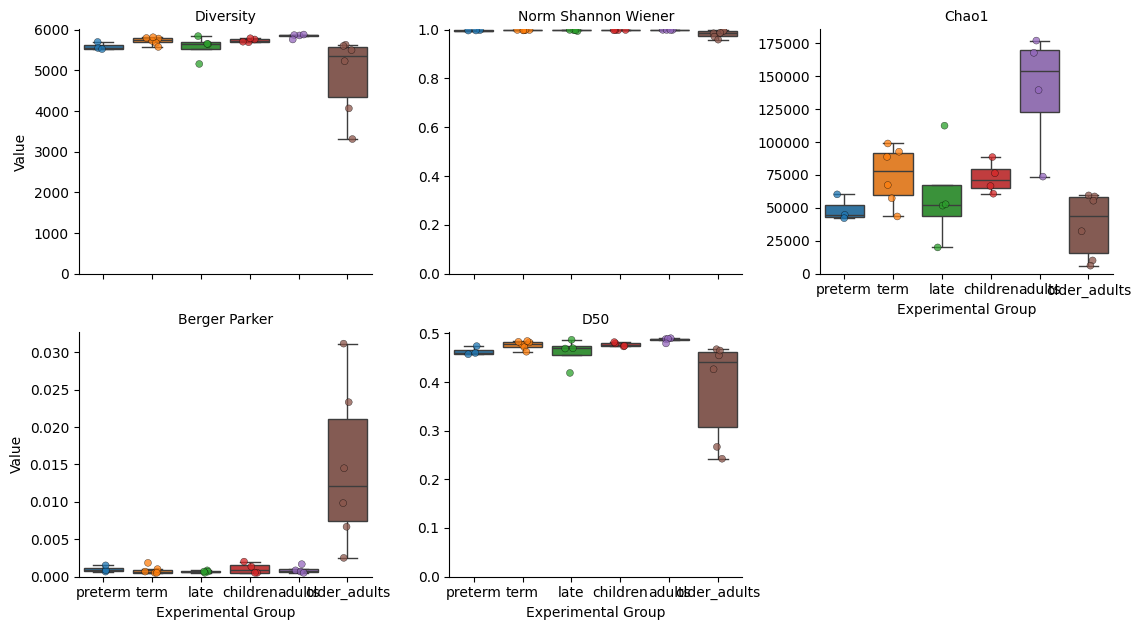

Using 4 cores


CalcRarefactionPoints |##################################################| 27/27 calcultaion(s) processed


CalcDiversityStats settings: seed=None, downsample=3000, top=None, iterations=3
Calcultating stats for original clonosets
_________________________________________
Using 4 cores


CalcClonosetStats |##################################################| 27/27 calcultaion(s) processed


WARNING! Following samples have NaN downsample counts ('umi_func'): UCB3_nCD8_TRB_1, UCB11_nCD8_TRB_1, c4_nCD8_TRB_1, UCB13_nCD8_TRB_1, UCB12_nCD8_TRB_1, o1_nCD8_TRB_1, UCB4_nCD8_TRB_1, UCB10_nCD8_TRB_1, c1_nCD8_TRB_1, a6_nCD8_TRB_1, UCB2_nCD8_TRB_1, o7_nCD8_TRB_1, UCB7_nCD8_TRB_1, UCB9_nCD8_TRB_1, o3_nCD8_TRB_1, a12_nCD8_TRB_1, UCB6_nCD8_TRB_1, o6_nCD8_TRB_1, UCB8_nCD8_TRB_1, a4_nCD8_TRB_1, o2_nCD8_TRB_1, UCB1_nCD8_TRB_2, c2_nCD8_TRB_1, c5_nCD8_TRB_1, o4_nCD8_TRB_1, UCB5_nCD8_TRB_1, a5_nCD8_TRB_1
These samples will be counted by reads instead
WARNING! Random filter is applied, but random seed is not set. This may lead to non-reproducible results.
You may set the seed (of any hashable type) by specifying 'seed='
Using 4 cores


CalcDiversityStats |##################################################| 27/27 calcultaion(s) processed


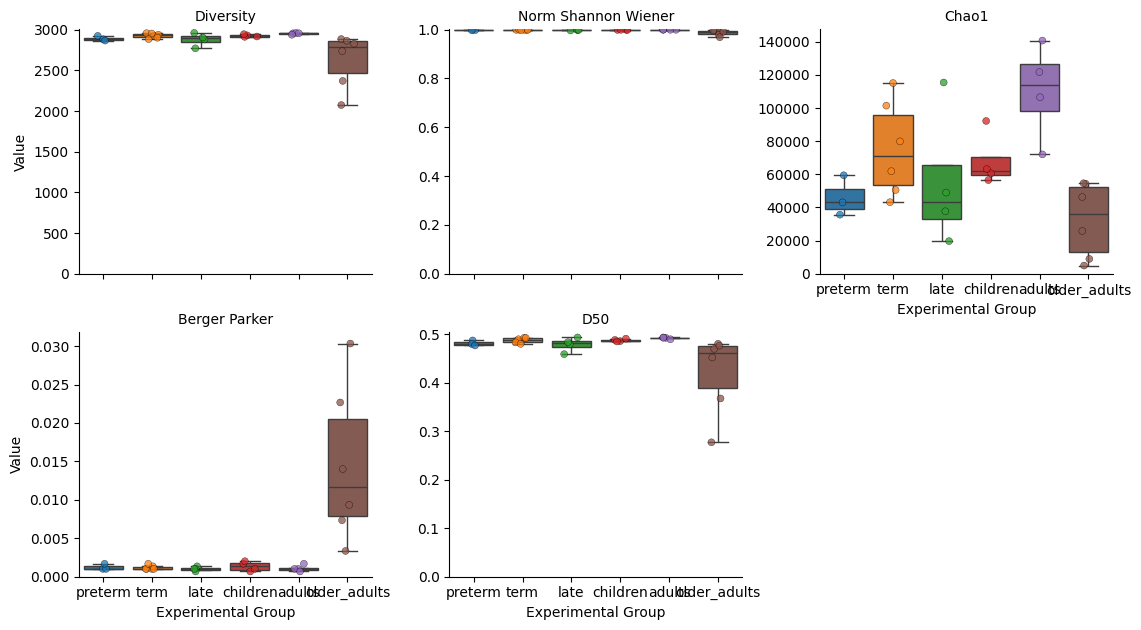

In [10]:
div_cd8_main = stats.calc_diversity_stats(clonosets_cd8, cl_filter=ds_cd8_main, cpu=4)
rsplot.diversity_stats(div_cd8_main, metadata=metadata, group="experimental_group")
plt.show()

rare_cd8 = stats.calc_rarefaction_curve(clonosets_cd8, cl_filter=func_filter, cpu=4)
rsplot.rarefaction_curve(rare_cd8)
plt.show()

# смотрим, что будет при downsample=3000
div_cd8_alt = stats.calc_diversity_stats(clonosets_cd8, cl_filter=ds_cd8_alt, cpu=4)
rsplot.diversity_stats(div_cd8_alt, metadata=metadata, group="experimental_group")
plt.show()

### Бета-разнообразие (F2) и MDS (nCD8)

In [11]:
beta_cd8 = beta.metrics(clonosets_cd8, cl_filter=ds_cd8_main, cpu=4)
rsplot.beta_table(beta_cd8)
plt.show()

mds_cd8 = beta.mds(beta_cd8, metric="f2")
rsplot.beta_mds(mds_cd8, metadata=metadata, group="experimental_group")
plt.show()

Intersecting clones in clonosets
--------------------------------------------------
Overlap type: aaV


Reading clonosets |##################################################| 27/27 sample(s) processed
Using 4 cores


Intersecting clonosets |##################################################| 351/351 pairs processed


## Выводы по nCD4 и nCD8

В целом картина по возрасту в `nCD4` и `nCD8` похожа на то, что было в `nTreg`, но со своими нюансами.

У недоношенных (`preterm`) в обеих популяциях CDR3 заметно короче, среднее число вставок меньше, а доля последовательностей вообще без вставок (`zero_insert_freq`) выше, чем у доношенных и тем более у детей и взрослых. Это хорошо ложится на биологию: на ранних сроках гестации активность TdT ещё низкая, поэтому случайных N-нуклеотидов вставляется мало.

Из-за этого же в пуповинной крови (особенно в `preterm`) выше конвергенция и попарное сходство F2 между разными донорами — без длинных случайных вставок чаще независимо собираются одинаковые последовательности. С возрастом репертуары становятся более «индивидуальными», и на MDS группы пуповинной и периферической крови расходятся.

Главное отличие между `nCD4` и `nCD8` видно по альфа-разнообразию у пожилых (`older_adults`). Если наивные `nCD4` держат довольно высокое разнообразие почти всю жизнь, то в `nCD8` у `older_adults` разнообразие проседает гораздо сильнее, а клональность растёт — сказывается инволюция тимуса и гомеостатическая экспансия отдельных CD8-клонов.

Когда уменьшили `downsample` примерно вдвое (5500 → 2500 для `nCD4` и 6000 → 3000 для `nCD8`), абсолютные числа наблюдаемых клонотипов и Chao1, естественно, упали, потому что в меньшую выборку попадает меньше редких клонов. Но сами соотношения между возрастными группами не сломались — тренды остались теми же.